# D02 — Données et audit de GLD

Ce notebook présente les données utilisées dans notre projet,
leur provenance et les contrôles de qualité.

- Actif : GLD — SPDR Gold Shares.
- Source : Yahoo Finance via yfinance.
- Fréquence : journalière.
- Période demandée : du 01/01/2018 au 30/10/2026 inclus.
- Prix OHLC ajustés avec auto_adjust=True.

Les données sont chargées depuis un snapshot local daté.
Aucun modèle n'est entraîné dans ce notebook.

## 1. Préparer l’environnement et importer les fonctions

Cette étape permet au notebook d’utiliser les fonctions définies dans
`src/data.py`, sans recopier leur code.

Si le projet n’est pas trouvé, une erreur explicite est affichée.

**Résultat attendu :** le chemin de la racine du projet s’affiche.


In [4]:
from pathlib import Path
import sys
import json

# Le notebook peut démarrer depuis notebooks/ ou depuis la racine.
current_folder = Path.cwd()

if (current_folder / "src" / "data.py").exists():
    PROJECT_ROOT = current_folder
elif (current_folder.parent / "src" / "data.py").exists():
    PROJECT_ROOT = current_folder.parent
else:
    raise FileNotFoundError(
        "Ouvre le notebook depuis le dossier du projet ou notebooks/."
    )

# Permet à Python de trouver notre package src.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_snapshot, audit_data

print("Racine du projet :", PROJECT_ROOT)

Racine du projet : c:\Users\ilyas\Desktop\idld\idldS3\trading intelligent\GLD Quant Lab


## 2. Identifier les snapshots disponibles

Un snapshot est une copie locale des données, conservée dans un dossier daté.
Il permet de reproduire l’analyse sans refaire une requête à Yahoo Finance.

Si aucun fichier n’est trouvé, le programme indique qu’il faut d’abord
exécuter le script de collecte avec `python -m src.data`.

**Résultat attendu :** la liste des snapshots disponibles.

Cette étape liste les fichiers ; elle ne charge pas encore leur contenu.

In [5]:
snapshots = sorted(
    (PROJECT_ROOT / "data" / "raw").glob("GLD_*/GLD_daily.csv")
)

if not snapshots:
    raise FileNotFoundError(
        "Aucun snapshot trouvé. Lance d'abord : python -m src.data"
    )

for path in snapshots:
    print(path.relative_to(PROJECT_ROOT))

data\raw\GLD_20261115T154114487177Z\GLD_daily.csv


## 3. Choisir et charger les données

Nous sélectionnons explicitement un snapshot parmi les fichiers disponibles.


**Résultat attendu :** les cinq premières observations du snapshot.
Aucune donnée n’est téléchargée ou nettoyée à cette étape.

In [6]:
SNAPSHOT = "data/raw/GLD_20261115T154114487177Z/GLD_daily.csv"

csv_path = PROJECT_ROOT / SNAPSHOT

df = load_snapshot(csv_path)

df.head()

,Date,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,2018-01-02,0.0,125.150002,0.0,125.180000,124.389999,124.660004,0.0,11762500
1,2018-01-03,0.0,124.820000,0.0,125.089996,124.099998,125.050003,0.0,7904300
2,2018-01-04,0.0,125.459999,0.0,125.849998,124.739998,124.889999,0.0,7329700
3,2018-01-05,0.0,125.330002,0.0,125.480003,124.830002,124.930000,0.0,5739900
4,2018-01-08,0.0,125.309998,0.0,125.320000,124.900002,125.199997,0.0,3566700


## 4. Vérifier la provenance des données

Les métadonnées décrivent l’origine et les conditions de récupération
du snapshot. Elles sont enregistrées dans `metadata.json`, à côté du CSV.


**Résultat attendu :** les informations de provenance enregistrées
au moment de la collecte.

La période observée peut différer légèrement de la période demandée,
notamment lorsque les dates de début ou de fin ne sont pas des séances
boursières.

**Limite :** afficher les métadonnées ne vérifie pas que le CSV
n’a pas été modifié depuis sa création.

In [7]:
metadata_path = csv_path.parent / "metadata.json"

with metadata_path.open("r", encoding="utf-8") as file:
    metadata = json.load(file)

print("Source :", metadata["source"])
print("Actif :", metadata["symbol"])
print("Date d'acquisition UTC :", metadata["acquired_at_utc"])
print("Première séance :", metadata["observed_first_date"])
print("Dernière séance :", metadata["observed_last_date"])
print("Nombre de lignes :", metadata["rows"])
print("Ajustement :", metadata["adjustment_convention"])

Source : Yahoo Finance via yfinance
Actif : GLD
Date d'acquisition UTC : 2026-11-15T15:41:14.487177+00:00
Première séance : 2018-01-02
Dernière séance : 2026-10-30
Nombre de lignes : 2220
Ajustement : OHLC ajustés par yfinance


## 5. Réaliser les premiers contrôles qualité

Avant d’utiliser les données, nous recherchons les anomalies qui pourraient
fausser les calculs et les futurs modèles.

Le résultat est enregistré dans `quality_report`, puis affiché sous forme
de tableau.

**Comment interpréter les résultats ?**
- Un compteur à 0 signifie que le contrôle n’a détecté aucun cas.
- Un compteur positif indique des observations à examiner.
- Pour l’ordre chronologique, 0 signifie que l’ordre est respecté et 1
  qu’il ne l’est pas : ce n’est pas un nombre de lignes.
- Une même ligne peut déclencher plusieurs contrôles. Il ne faut donc pas
  additionner tous les compteurs pour obtenir un nombre de lignes incorrectes.

**Résultat attendu :** un tableau des premiers contrôles qualité.

Cette étape ne supprime et ne corrige aucune donnée. Elle ne vérifie pas
encore les séances manquantes ni toutes les anomalies possibles.

In [8]:
quality_report = audit_data(df)

quality_report

,Controle,Nombre
0,Lignes avec au moins une valeur manquante,0
1,Dates dupliquées supplémentaires,0
2,Ordre chronologique incorrect,0
3,Lignes avec un prix nul ou négatif,0
4,Lignes avec un High incohérent,0
5,Lignes avec un Low incohérent,0
6,Lignes avec un volume négatif,0
7,Lignes avec un volume nul — à examiner,0


## 7. Visualiser les prix et les volumes de GLD

Nous traçons deux graphiques pour examiner le comportement des données :

1. Le prix de clôture ajusté montre l’évolution de GLD pendant la période.
2. Le volume montre le nombre de parts échangées lors de chaque séance.

Nous recherchons notamment :
- Des prix isolés ou des changements brusques à examiner.
- Des volumes nuls ou particulièrement élevés.
- Des interruptions visibles dans les données.

Une variation importante n’est pas automatiquement une erreur :
elle peut correspondre à un mouvement réel du marché.

Le code trie une copie des données par date pour l’affichage.
Le tableau original `df` reste inchangé.

**Limite :** la courbe relie les observations disponibles.
Elle ne permet donc pas, à elle seule, de détecter toutes les séances manquantes.

**Résultat attendu :** deux graphiques partageant le même axe des dates.

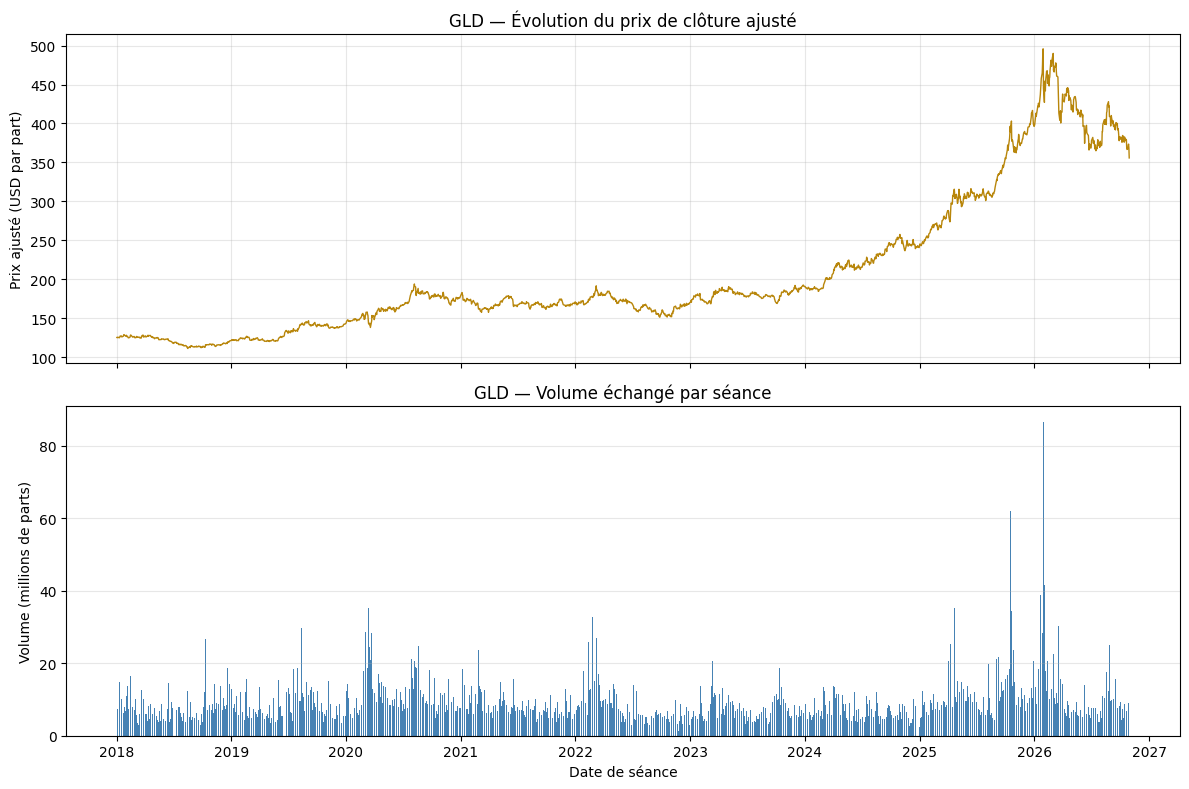

In [9]:
import matplotlib.pyplot as plt

# Copier et trier les données uniquement pour l'affichage.
plot_df = df.sort_values("Date").copy()

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 8),
    sharex=True
)

# Premier graphique : clôture ajustée.
axes[0].plot(
    plot_df["Date"],
    plot_df["Close"],
    color="darkgoldenrod",
    linewidth=1
)

axes[0].set_title("GLD — Évolution du prix de clôture ajusté")
axes[0].set_ylabel("Prix ajusté (USD par part)")
axes[0].grid(alpha=0.3)

# Deuxième graphique : volume exprimé en millions de parts.
axes[1].bar(
    plot_df["Date"],
    plot_df["Volume"] / 1_000_000,
    color="steelblue",
    width=1
)

axes[1].set_title("GLD — Volume échangé par séance")
axes[1].set_ylabel("Volume (millions de parts)")
axes[1].set_xlabel("Date de séance")
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()

plt.show()

##  Interprétation des graphiques

### Évolution du prix

Sur la période affichée, le prix de clôture ajusté de GLD présente
une hausse globale, avec plusieurs phases de baisse.

Après une baisse en 2018, le prix progresse jusqu’en 2020.
Entre 2020 et 2023, il fluctue sans hausse durable comparable
à celle observée ensuite.

La progression s’accentue à partir de 2024. Le prix approche
500 USD au début de 2026, puis recule fortement et termine
la période affichée autour de 360 USD.

Ces valeurs sont approximatives et lues sur le graphique.
Les valeurs exactes doivent être calculées à partir du dataset.

### Évolution du volume

Le volume varie selon les séances et présente plusieurs pics,
notamment autour de 2020, 2022 et de la fin de 2025 au début de 2026.

Ces pics correspondent à une activité d’échange plus importante.
Ils ne permettent pas, à eux seuls, de déterminer la direction
future du prix ni d’expliquer la cause des mouvements.

### Conséquences pour notre projet

Les phases de hausse et de baisse montrent l’intérêt d’étudier
le risque associé à une position sur GLD.

Cependant, des variations plus grandes en dollars ne prouvent pas
automatiquement une volatilité plus élevée en pourcentage.
Nous devrons analyser les rendements pour mesurer cette volatilité.

### Limites de la vérification visuelle

Le graphique ne suffit pas à certifier la qualité des données.
Les mouvements importants et les pics de volume devront être
examinés dans le tableau et, si nécessaire, comparés à la source.

Les séances manquantes ne sont pas forcément visibles, car la courbe
relie les observations disponibles.

## 8. Sauvegarder le graphique de cohérence

Nous conservons la figure dans `reports/figures/`, dans un sous-dossier
portant le nom du snapshot utilisé.

Cela permet de relier le graphique au fichier de données analysé
et de l’intégrer au rapport D02.

Le code crée le dossier s’il n’existe pas, puis sauvegarde la figure
au format PNG avec une résolution de 150 dpi.

Une nouvelle sauvegarde pour le même snapshot remplace cette figure.

In [10]:
figure_folder = (
    PROJECT_ROOT
    / "reports"
    / "figures"
    / csv_path.parent.name
)

figure_folder.mkdir(parents=True, exist_ok=True)

figure_path = figure_folder / "gld_price_volume.png"

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

print("Figure sauvegardée :", figure_path)

Figure sauvegardée : c:\Users\ilyas\Desktop\idld\idldS3\trading intelligent\GLD Quant Lab\reports\figures\GLD_20261115T154114487177Z\gld_price_volume.png


## 10. Identifier les anomalies et vérifier les séances manquantes

Nous rechargeons le CSV sélectionné et vérifions son empreinte pour savoir
s’il correspond au fichier sauvegardé lors de la collecte.

Nous comparons ensuite les dates du CSV aux séances de Bourse attendues
sur toute la période demandée. Cette comparaison permet de détecter une
séance absente même si un doublon conserve le bon nombre total de lignes.

Pour chaque ligne signalée, nous conservons son numéro dans le CSV, sa date,
ses valeurs et le motif du contrôle. Un volume nul, par exemple, est signalé
pour vérification. Le snapshot brut reste intact.

In [12]:
from IPython.display import Markdown, display
from src.audit_d02 import audit_snapshot


anomalies, seances_manquantes, rapport = audit_snapshot(
    csv_path,
    PROJECT_ROOT / "reports"
)

display(Markdown(rapport.read_text(encoding="utf-8")))

print("Premiers signalements dans le CSV")
display(anomalies.head(10))

print("Premières séances attendues mais absentes")
display(seances_manquantes.head(10))

# D02 — Conclusion de l’audit de GLD

Le fichier `GLD_20261115T154114487177Z/GLD_daily.csv` a été relu localement.
La fenêtre demandée va du 01/01/2018 au 30/10/2026 inclus.
Le CSV correspond à l’empreinte enregistrée lors de la collecte.

| Indicateur | Résultat |
|---|---:|
| Observations lues dans le CSV | 2220 |
| Séances attendues selon le calendrier NYSE | 2220 |
| Séances attendues présentes au moins une fois | 2220 |
| Séances attendues absentes | 0 |
| Lignes distinctes à examiner | 0 |
| Signalements sur ces lignes | 0 |

La première séance attendue présente est celle du 02/01/2018 et la dernière celle du 30/10/2026.
Les contrôles de dates, de valeurs, de prix OHLC et de volume n’ont signalé aucune ligne du CSV.
Toutes les dates de séance attendues figurent dans le CSV.

Le snapshot brut a été conservé. La comparaison porte sur les dates d’ouverture du marché, y compris les séances écourtées. Une séance présente peut contenir un prix à vérifier.

Calendrier NYSE de pandas_market_calendars 5.6.1. Lecture avec pandas 2.3.3.
Empreinte SHA-256 du CSV examiné `252ced6250c58139a01ea8493eedba65a876be593fe21ba94f6d416ff53f70fa`.


Premiers signalements dans le CSV


,Ligne_CSV,Date,Motif,Champ,Suite_proposee,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume


Premières séances attendues mais absentes


,Date
